# Twitter Sentiment Analysis

### Project Overview

This project focuses on analyzing the sentiment of tweets using Natural Language Processing (NLP).

A publicly available Twitter dataset from Kaggle is used to analyze different opinions and expressions. TextBlob is applied to calculate the polarity of tweet text and classify tweets into Positive, Negative, or Neutral categories.

### Objectives

- Collect a Twitter dataset from Kaggle.
- Explore and preprocess tweet text.
- Perform sentiment analysis using TextBlob.
- Calculate sentiment polarity scores.
- Classify tweets as Positive, Negative, or Neutral.
- Visualize and analyze sentiment distribution.

### Technologies Used

- Python
- Pandas
- NumPy
- TextBlob
- Matplotlib
- Seaborn

### Methodology

The project uses a rule-based sentiment analysis approach with TextBlob. The polarity score is used to determine the sentiment of each tweet.

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from textblob import TextBlob

import re
import warnings

warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
!pip install textblob

## Dataset Loading and Exploration

The Twitter Entity Sentiment Analysis dataset is obtained from Kaggle. It contains tweets associated with different entities and sentiment labels.

In this section, we load the dataset, examine its structure, understand its columns, and check for missing or duplicate records.

In [7]:
# Load the Kaggle training dataset

tweets = pd.read_csv('/content/twitter_training.csv', header=None)

# Assign column names
tweets.columns = ['Tweet_ID', 'Entity', 'Sentiment', 'Tweet']

# Display first five records
display(tweets.head())

,Tweet_ID,Entity,Sentiment,Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [8]:
# Check dataset dimensions

print("Dataset Shape:", tweets.shape)

# Check column information
print("\nDataset Information:")
tweets.info()

# Statistical summary
print("\nDataset Summary:")
display(tweets.describe(include='all'))

# Check missing values
print("\nMissing Values:")
print(tweets.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", tweets.duplicated().sum())

# Check sentiment categories
print("\nSentiment Distribution:")
print(tweets['Sentiment'].value_counts())

Dataset Shape: (74682, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Tweet_ID   74682 non-null  int64 
 1   Entity     74682 non-null  object
 2   Sentiment  74682 non-null  object
 3   Tweet      73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB

Dataset Summary:


,Tweet_ID,Entity,Sentiment,Tweet
count,74682.000000,74682,74682,73996
unique,NaN,32,4,69491
top,NaN,Microsoft,Negative,"At the same time, despite the fact that there ..."
freq,NaN,2400,22542,172
mean,6432.586165,NaN,NaN,NaN
std,3740.427870,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN
25%,3195.000000,NaN,NaN,NaN
50%,6422.000000,NaN,NaN,NaN
75%,9601.000000,NaN,NaN,NaN



Missing Values:
Tweet_ID       0
Entity         0
Sentiment      0
Tweet        686
dtype: int64

Duplicate Records: 2700

Sentiment Distribution:
Sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64


## Data Cleaning and Preprocessing

Data preprocessing is an important step in sentiment analysis. In this section, we handle missing values, remove duplicate records, exclude irrelevant tweets, and clean the tweet text by removing URLs, mentions, and unnecessary special characters.

In [9]:
# Remove rows with missing tweet text or sentiment
tweets.dropna(subset=['Tweet', 'Sentiment'], inplace=True)

# Remove duplicate records
tweets.drop_duplicates(inplace=True)

# Keep only the required sentiment categories
tweets = tweets[
    tweets['Sentiment'].isin(['Positive', 'Negative', 'Neutral'])
].copy()

# Reset index
tweets.reset_index(drop=True, inplace=True)

print("Dataset cleaned successfully!")
print("Remaining records:", len(tweets))

print("\nSentiment Categories:")
print(tweets['Sentiment'].value_counts())

Dataset cleaned successfully!
Remaining records: 59119

Sentiment Categories:
Sentiment
Negative    21698
Positive    19713
Neutral     17708
Name: count, dtype: int64


In [10]:
# Function to clean tweet text

def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()


# Apply text cleaning
tweets['Cleaned_Tweet'] = tweets['Tweet'].apply(clean_tweet)

# Display original and cleaned tweets
display(tweets[['Tweet', 'Cleaned_Tweet']].head(10))

,Tweet,Cleaned_Tweet
0,im getting on borderlands and i will murder yo...,im getting on borderlands and i will murder yo...
1,I am coming to the borders and I will kill you...,i am coming to the borders and i will kill you...
2,im getting on borderlands and i will kill you ...,im getting on borderlands and i will kill you all
3,im coming on borderlands and i will murder you...,im coming on borderlands and i will murder you...
4,im getting on borderlands 2 and i will murder ...,im getting on borderlands and i will murder yo...
5,im getting into borderlands and i can murder y...,im getting into borderlands and i can murder y...
6,So I spent a few hours making something for fu...,so i spent a few hours making something for fu...
7,So I spent a couple of hours doing something f...,so i spent a couple of hours doing something f...
8,So I spent a few hours doing something for fun...,so i spent a few hours doing something for fun...
9,So I spent a few hours making something for fu...,so i spent a few hours making something for fu...


In [11]:
# Check missing values after cleaning
print("Missing Values:")
print(tweets.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", tweets.duplicated().sum())

# Display final dataset information
print("\nFinal Dataset Shape:", tweets.shape)

display(tweets.head())

Missing Values:
Tweet_ID         0
Entity           0
Sentiment        0
Tweet            0
Cleaned_Tweet    0
dtype: int64

Duplicate Records: 0

Final Dataset Shape: (59119, 5)


,Tweet_ID,Entity,Sentiment,Tweet,Cleaned_Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...,i am coming to the borders and i will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...,im getting on borderlands and i will kill you all
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...,im getting on borderlands and i will murder yo...


## Sentiment Analysis Using TextBlob

TextBlob is a Python library used for processing textual data. It calculates a polarity score for each tweet to identify its sentiment.

The polarity score ranges from -1 to +1:

- Positive polarity indicates positive sentiment.
- Negative polarity indicates negative sentiment.
- Zero polarity indicates neutral sentiment.

In this section, TextBlob will analyze each cleaned tweet and generate its sentiment polarity score.

In [12]:
# Calculate polarity score using TextBlob

tweets['Polarity'] = tweets['Cleaned_Tweet'].apply(
    lambda text: TextBlob(text).sentiment.polarity
)

# Display tweet polarity scores
display(tweets[['Tweet', 'Polarity']].head(10))

,Tweet,Polarity
0,im getting on borderlands and i will murder yo...,0.000000
1,I am coming to the borders and I will kill you...,0.000000
2,im getting on borderlands and i will kill you ...,0.000000
3,im coming on borderlands and i will murder you...,0.000000
4,im getting on borderlands 2 and i will murder ...,0.000000
5,im getting into borderlands and i can murder y...,0.000000
6,So I spent a few hours making something for fu...,0.239286
7,So I spent a couple of hours doing something f...,0.295833
8,So I spent a few hours doing something for fun...,0.180000
9,So I spent a few hours making something for fu...,0.239286


## Sentiment Classification

Based on the polarity scores calculated by TextBlob, each tweet is classified into one of three sentiment categories: Positive, Negative, or Neutral.

In [13]:
# Function to classify sentiment

def classify_sentiment(polarity):
    if polarity > 0:
        return 'Positive'
    elif polarity < 0:
        return 'Negative'
    else:
        return 'Neutral'


# Apply sentiment classification
tweets['Predicted_Sentiment'] = tweets['Polarity'].apply(
    classify_sentiment
)

# Display classification results
display(
    tweets[['Tweet', 'Polarity', 'Sentiment', 'Predicted_Sentiment']].head(15)
)

,Tweet,Polarity,Sentiment,Predicted_Sentiment
0,im getting on borderlands and i will murder yo...,0.000000,Positive,Neutral
1,I am coming to the borders and I will kill you...,0.000000,Positive,Neutral
2,im getting on borderlands and i will kill you ...,0.000000,Positive,Neutral
3,im coming on borderlands and i will murder you...,0.000000,Positive,Neutral
4,im getting on borderlands 2 and i will murder ...,0.000000,Positive,Neutral
5,im getting into borderlands and i can murder y...,0.000000,Positive,Neutral
6,So I spent a few hours making something for fu...,0.239286,Positive,Positive
7,So I spent a couple of hours doing something f...,0.295833,Positive,Positive
8,So I spent a few hours doing something for fun...,0.180000,Positive,Positive
9,So I spent a few hours making something for fu...,0.239286,Positive,Positive


In [14]:
# Count predicted sentiment categories

predicted_counts = tweets['Predicted_Sentiment'].value_counts()

print("Predicted Sentiment Distribution:")
print(predicted_counts)

print("\nTotal Analyzed Tweets:", len(tweets))

Predicted Sentiment Distribution:
Predicted_Sentiment
Positive    26831
Negative    17394
Neutral     14894
Name: count, dtype: int64

Total Analyzed Tweets: 59119


## Sentiment Data Visualization

Data visualization helps us understand the distribution of sentiments in the analyzed tweets. In this section, we create graphical representations to compare Positive, Negative, and Neutral sentiments predicted by TextBlob.

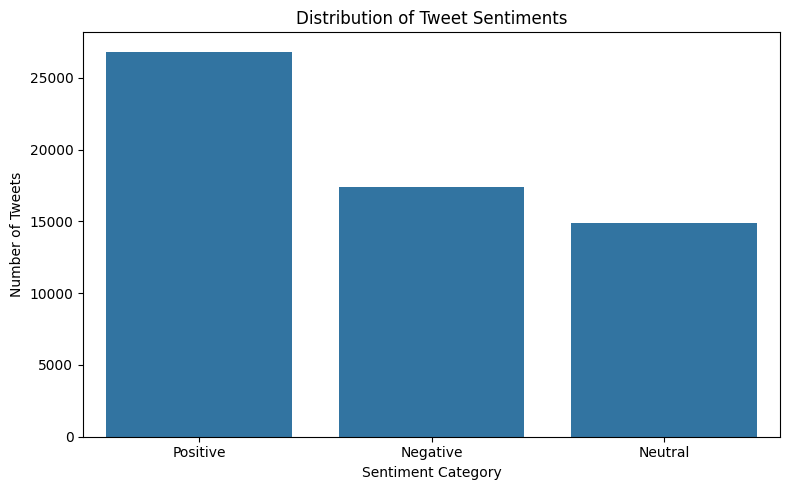

In [15]:
# Calculate predicted sentiment counts

sentiment_counts = tweets['Predicted_Sentiment'].value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title('Distribution of Tweet Sentiments')
plt.xlabel('Sentiment Category')
plt.ylabel('Number of Tweets')
plt.tight_layout()
plt.show()

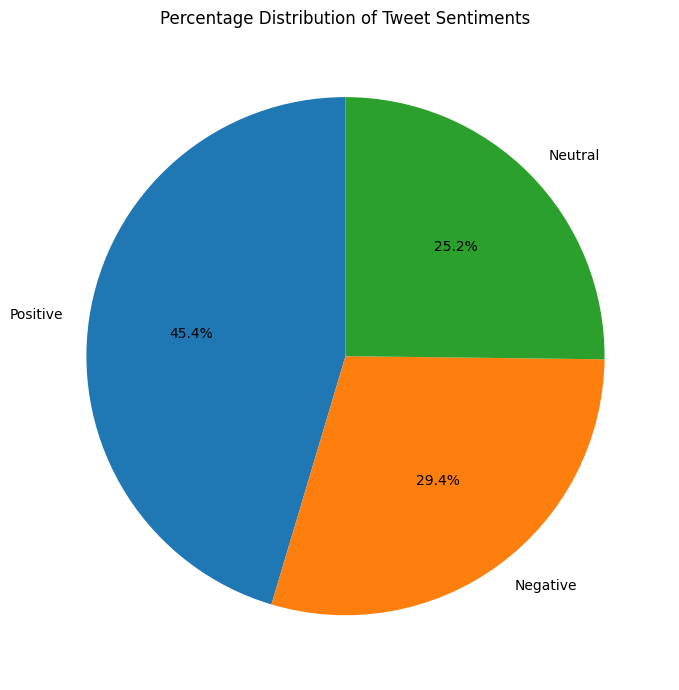

In [16]:
# Create pie chart

plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts.values,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage Distribution of Tweet Sentiments')
plt.tight_layout()
plt.show()

## Comparison of Original and Predicted Sentiments

The Kaggle dataset already contains original sentiment labels. We compare these labels with the sentiments predicted by TextBlob to understand the differences between the actual dataset categories and our rule-based predictions.

,Original Sentiment,Predicted Sentiment
Negative,21698,17394
Neutral,17708,14894
Positive,19713,26831


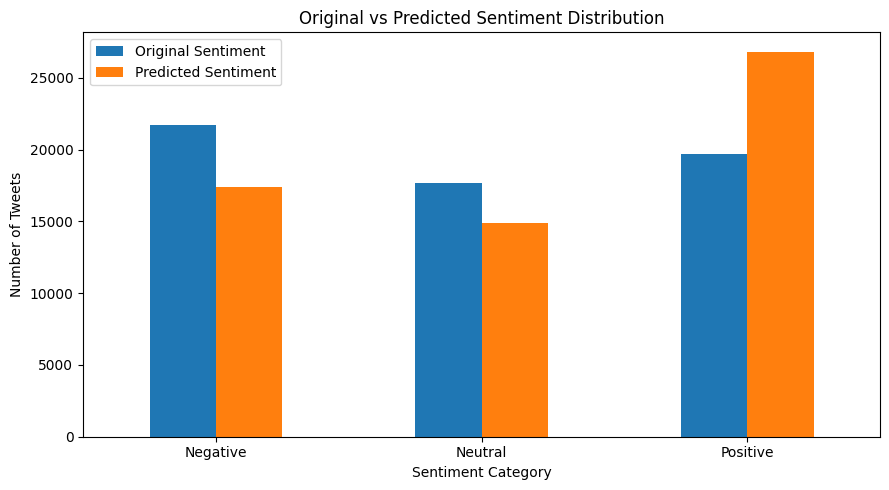

In [17]:
# Compare original and predicted sentiment counts

comparison = pd.DataFrame({
    'Original Sentiment': tweets['Sentiment'].value_counts(),
    'Predicted Sentiment': tweets['Predicted_Sentiment'].value_counts()
}).fillna(0)

display(comparison)

# Visualize comparison
comparison.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Original vs Predicted Sentiment Distribution')
plt.xlabel('Sentiment Category')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

## Model Evaluation

In this section, we evaluate the sentiment predictions generated by TextBlob by comparing them with the original sentiment labels provided in the Kaggle dataset.

We use accuracy, precision, recall, F1-score, and a confusion matrix to understand the performance of the sentiment analysis approach.

In [18]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Original and predicted labels
y_true = tweets['Sentiment']
y_pred = tweets['Predicted_Sentiment']

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)

print("TextBlob Sentiment Analysis Accuracy:",
      round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

TextBlob Sentiment Analysis Accuracy: 47.98 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.59      0.47      0.52     21698
     Neutral       0.36      0.30      0.33     17708
    Positive       0.48      0.65      0.55     19713

    accuracy                           0.48     59119
   macro avg       0.47      0.47      0.47     59119
weighted avg       0.48      0.48      0.47     59119



## Confusion Matrix

A confusion matrix is used to compare the original sentiment labels with the predicted sentiment labels. It helps identify correctly and incorrectly classified tweets across the three sentiment categories.

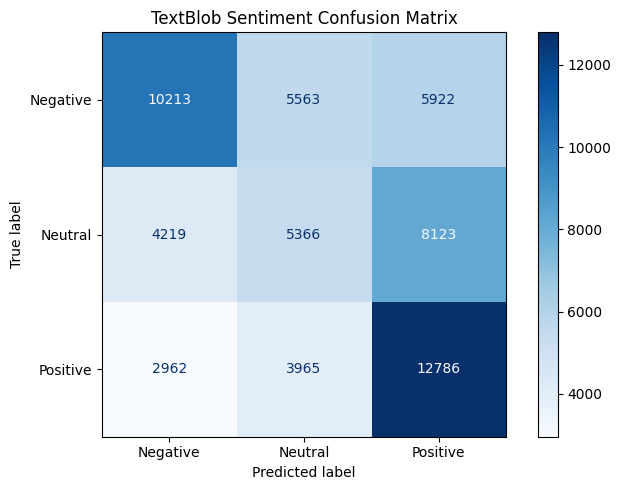

In [19]:
# Generate confusion matrix

labels = ['Negative', 'Neutral', 'Positive']

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')

plt.title('TextBlob Sentiment Confusion Matrix')
plt.tight_layout()
plt.show()

## Sentiment Analysis Results

This section summarizes the results obtained from TextBlob sentiment analysis. It examines the number of Positive, Negative, and Neutral tweets and identifies the overall sentiment trend in the dataset.

In [20]:
# Calculate sentiment statistics

sentiment_summary = tweets['Predicted_Sentiment'].value_counts()

total_tweets = len(tweets)

print("Total Tweets Analyzed:", total_tweets)

print("\nSentiment Summary:")

for sentiment, count in sentiment_summary.items():
    percentage = (count / total_tweets) * 100

    print(
        f"{sentiment}: {count} tweets "
        f"({percentage:.2f}%)"
    )

# Identify the most common sentiment
overall_sentiment = sentiment_summary.idxmax()

print("\nMost Common Sentiment:", overall_sentiment)

Total Tweets Analyzed: 59119

Sentiment Summary:
Positive: 26831 tweets (45.38%)
Negative: 17394 tweets (29.42%)
Neutral: 14894 tweets (25.19%)

Most Common Sentiment: Positive


## Sample Sentiment Predictions

The following examples display the original tweet text, its calculated polarity score, the original Kaggle sentiment label, and the sentiment predicted by TextBlob.

In [21]:
# Display sample sentiment predictions

sample_predictions = tweets[
    ['Tweet', 'Sentiment', 'Polarity', 'Predicted_Sentiment']
].sample(10, random_state=42)

display(sample_predictions)

,Tweet,Sentiment,Polarity,Predicted_Sentiment
29526,"We have a few people lined up, but come in and...",Neutral,0.300000,Positive
54337,My word this baby looks beautiful!!.,Positive,0.850000,Positive
34795,I'm sure I got a Cal like that during my time ...,Positive,0.200000,Positive
31354,I think his one's pretty good,Positive,0.475000,Positive
30033,PLEASE OF STOP,Negative,0.000000,Neutral
33233,PUBG is the best game to date.,Positive,0.300000,Positive
42983,Damn call of duty did black black lives matter...,Positive,0.107483,Positive
7613,"The Xbox Series X Has 60 FPS As 'Standard', Bu...",Neutral,0.000000,Neutral
14894,*NEW YORK*.. The Plague that Broke the World o...,Negative,0.097727,Positive
31411,"In multiplayer mode, I don't see any player he...",Negative,-0.125000,Negative


## Key Findings

- The project successfully analyzed tweets using TextBlob.
- Each tweet received a polarity score between -1 and +1.
- Tweets were classified into Positive, Negative, and Neutral categories.
- Sentiment distribution graphs helped identify the most common predicted sentiment.
- Evaluation metrics and the confusion matrix showed how TextBlob predictions compared with the original Kaggle labels.
- Rule-based sentiment analysis may produce different results from human-labelled datasets because it does not fully understand context, sarcasm, or complex expressions.

## Conclusion

The Twitter Sentiment Analysis project successfully demonstrates how Natural Language Processing can be used to identify opinions and emotions expressed in tweets.

A publicly available Kaggle dataset was used, and TextBlob was applied to calculate polarity scores and classify tweets into Positive, Negative, and Neutral categories.

The project also included data cleaning, sentiment visualization, and performance evaluation using accuracy, precision, recall, F1-score, and a confusion matrix.

Overall, this project provides practical experience in text preprocessing, rule-based sentiment analysis, and data visualization using Python.